# Обучение без учителя: кластеризация и ассоциативные правила



Еще раз напоминаю, что Вы можете оставить свою анонимную обратную связь по курсу здесь, это очень важно для меня, с ней я смогу скорректировать учебный процесс, чтобы он был комфортным для всех: https://forms.yandex.ru/u/6a8be2b94936399cf9d46765

Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

Скрипт подготовлен по материалам: [Проворовой (Радыгиной) Анны Александровны](https://www.hse.ru/staff/provorovaaa/)

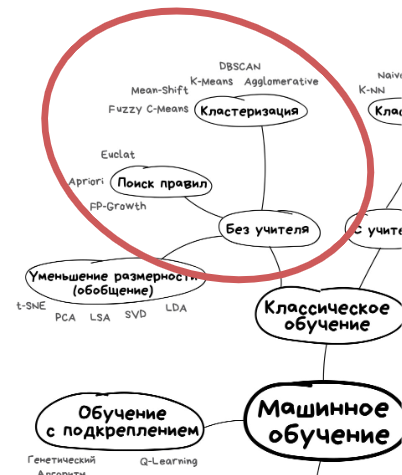

## Контекст нашей задачи на сегодня

Рассмотрим данные интернет-магазина, содержащие информацию о транзакциях за период с 1 декабря 2010 года по 9 декабря 2011 года. Датасет содержит сведения о заказах, товарах, количестве и стоимости покупок, клиентах и странах. Всего — 541 909 записей о покупках.

Представим, что мы работаем аналитиками этого магазина. Компания хочет лучше понять поведение своих клиентов и особенности покупательского спроса.

Для этого мы задаём данным два разных вопроса.

**1. Какие бывают клиенты?**

Мы хотим понять, существуют ли в клиентской базе естественные группы покупателей, которые отличаются своим поведением.

Для этого описываем каждого клиента с помощью характеристик его покупок:

* сколько заказов он совершил;
* сколько всего потратил;
* сколько товаров в среднем покупает за один заказ;
* какова средняя стоимость заказа;
* сколько различных товаров покупал.

Затем с помощью кластеризации ищем группы клиентов с похожими характеристиками.

**2. Какие товары покупают вместе?**

Теперь нас интересует уже не клиент, а состав заказа.

Мы хотим понять, существуют ли устойчивые сочетания товаров: если покупатель приобрёл один товар, какие другие товары с ним часто оказываются в одном заказе?

С помощью ассоциативных правил ищем такие взаимосвязи и сравниваем их по:

* Support;
* Confidence;
* Lift.

## Загрузка данных

In [ ]:
# Подгрузим необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import gdown

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
data = online_retail.data.original

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)


Описание всех колонок:

| Название признака | Описание |
|--------------------------------------------|---------|
| **InvoiceNo** | 6-значный номер, который присваивается каждой транзакции и является уникальным. Если код начинается с буквы «c», это означает отмену транзакции. |
| **StockCode** | 5-значное целое число, однозначно присвоенное каждому отдельному продукту |
| **Description** | Наименование продукта |
| **Quantity** | Количество каждого продукта в каждой транзакции |
| **InvoiceDate** | Дата и время проведения каждой транзакции |
| **UnitPrice** | Цена за единицу товара |
| **CustomerID** | 5-значный номер, присвоенный каждому клиенту и не повторяющийся ни у кого другого |
| **Country** | Название страны, в которой проживает каждый клиент |


In [ ]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

print('Начало периода:', data['InvoiceDate'].min())
print('Конец периода:', data['InvoiceDate'].max())
print('Продолжительность:',
      data['InvoiceDate'].max() - data['InvoiceDate'].min())

In [ ]:
import pandas as pd
import numpy as np

df = data.copy()

# Дата в нужном формате
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Убираем клиентов без CustomerID
df = df.dropna(subset=['CustomerID'])

# Убираем отменённые заказы
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Оставляем реальные покупки
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Стоимость покупки
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [ ]:
# Данные о заказах
order_stats = (
    df.groupby(['CustomerID', 'InvoiceNo'])
      .agg(
          Items=('Quantity', 'sum'),
          OrderValue=('TotalPrice', 'sum')
      )
      .reset_index()
)

# 1. Количество заказов
frequency = (
    order_stats.groupby('CustomerID')
               .size()
               .rename('Purchases')
)

# 2. Общая сумма покупок
monetary = (
    df.groupby('CustomerID')['TotalPrice']
      .sum()
      .rename('TotalSpent')
)

# 3. Среднее количество товаров в заказе
avg_items = (
    order_stats.groupby('CustomerID')['Items']
               .mean()
               .rename('AvgItemsPerOrder')
)

# 4. Средний чек
avg_check = (
    order_stats.groupby('CustomerID')['OrderValue']
               .mean()
               .rename('AvgOrderValue')
)

# 5. Количество различных товаров
unique_products = (
    df.groupby('CustomerID')['StockCode']
      .nunique()
      .rename('UniqueProducts')
)

# 6. Средний интервал между покупками
order_dates = (
    df[['CustomerID', 'InvoiceNo', 'InvoiceDate']]
    .drop_duplicates()
    .sort_values(['CustomerID', 'InvoiceDate'])
)

order_dates['DaysBetweenPurchases'] = (
    order_dates.groupby('CustomerID')['InvoiceDate']
               .diff()
               .dt.total_seconds()
               / (24 * 60 * 60)
)

avg_interval = (
    order_dates.groupby('CustomerID')['DaysBetweenPurchases']
               .mean()
               .rename('AvgDaysBetweenPurchases')
)

# Объединяем все признаки
customer_features = pd.concat([
    frequency,
    monetary,
    avg_items,
    avg_check,
    unique_products,
    avg_interval
], axis=1).reset_index()

customer_features.head()

## Подготовка данных


In [ ]:
customer_features.describe().T

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

X = customer_features.drop(columns=['CustomerID'])

fig, axes = plt.subplots(len(X.columns), 2, figsize=(10, 3 * len(X.columns)))
for i, col in enumerate(X.columns):
  # Гистограмма
  sns.histplot(X[col].dropna(), ax=axes[i, 0], kde=True)
  axes[i, 0].set_title(f'Hist: {col}')
  # Боксплот
  sns.boxplot(y=X[col], ax=axes[i, 1])
  axes[i, 1].set_title(f'Boxplot: {col}')

plt.tight_layout()
plt.show()

In [ ]:
# Удаление выбросов с помощью здравого смысла

mask = (
    (customer_features['TotalSpent'] > 0)
    & (customer_features['TotalSpent'] < 10000)
    & (customer_features['Purchases'] < 50)
    & (customer_features['AvgOrderValue'] < 3000)
    & (customer_features['UniqueProducts'] < 300)
    & (customer_features['AvgItemsPerOrder'] < 1000)
)

customer_features = customer_features[mask].reset_index(drop=True)

## Первый вопрос: какие бывают клиенты и какие группы клиентов мы можем выделить?

### Кластеризация

**Кластеризация** — это метод **обучения без учителя** (unsupervised learning), цель которого — разбить набор объектов на группы (кластеры) так, чтобы объекты **внутри одной группы** были **похожи** друг на друга, а объекты из **разных групп** — **отличались**. В отличие от классификации, при кластеризации **нет заранее известных меток классов** — алгоритм сам выявляет структуру данных. Кластеризация широко применяется для сегментации клиентов, анализа изображений, сжатия данных, обнаружения аномалий и предварительного анализа датасетов.

**k-Means** — это один из самых популярных алгоритмов кластеризации, относящийся к методам обучения без учителя. Его цель — разбить данные на **k** групп (кластеров) так, чтобы каждый объект принадлежал тому кластеру, центр (центроид) которого находится ближе всего к нему.

Алгоритм работает итеративно:  
1. Случайно выбираются **k** начальных центроидов.  
2. Каждый объект приписывается к ближайшему центроиду (обычно по евклидову расстоянию).  
3. Центроиды пересчитываются как среднее всех объектов в кластере.  
4. Шаги 2–3 повторяются, пока центроиды не перестанут заметно смещаться или не будет достигнуто максимальное число итераций.

k-Means стремится минимизировать **сумму квадратов расстояний** от точек до центров их кластеров (инерцию). Алгоритм прост, быстр и эффективен для компактных, сферически распределённых кластеров, но чувствителен к выбору **k**, начальным центроидам и масштабу признаков.

Основные особенности подготовки данных для k-Means:
- **Только числовые признаки**: k-Means не работает с категориальными данными. Категориальные переменные нужно либо исключить, либо корректно закодировать (например, через one-hot encoding — с осторожностью, из-за роста размерности).
- **Обязательная стандартизация**: особенно если признаки измеряются в разных единицах или имеют разный порядок величины.
- **Отсутствие пропусков**: строки с пропущенными значениями следует удалить или заполнить (например, средним).
- **Чувствительность к выбросам**: k-Means стремится минимизировать сумму квадратов расстояний, поэтому выбросы могут сильно смещать центроиды. Иногда имеет смысл их обработать.
- **Форма кластеров**: k-Means лучше всего работает, когда кластеры **компактные, выпуклые и примерно одинакового размера**. Для сложных форм (например, полумесяцы, кольца) он может дать неудовлетворительный результат.

Таким образом, качественная предобработка — ключ к успешной кластеризации с помощью k-Means.

Подробнее про кластеризацию: https://contest.yandex.ru/tracks/ml/practical-topics/clustering

### Стандартизация признаков
**Стандартизация признаков** — это преобразование данных, при котором каждый признак приводится к нулевому среднему и единичной дисперсии (стандартному отклонению). Формула:  

$$z = \frac{x-μ}{σ}$$

где $μ$ — среднее значение признака, $σ$ — его стандартное отклонение.

Для **k-Means** стандартизация особенно важна, потому что алгоритм использует **евклидово расстояние** для измерения схожести объектов. Если признаки имеют разные масштабы (например, один измеряется в тысячах, а другой — в долях), то признак с бо́льшим размахом будет доминировать в расчёте расстояния, что исказит результат кластеризации.

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Оставляем для первой сегментации только 5 признаков (+ ID)
features = [
    'Purchases',
    'TotalSpent',
    'AvgItemsPerOrder',
    'AvgOrderValue',
    'UniqueProducts',
]

customer_ids = customer_features['CustomerID']
X = customer_features[features]

# Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

**Метод локтя (Elbow Method)** — это один из самых популярных и интуитивно понятных эвристических методов для определения оптимального числа кластеров ($k$) в алгоритмах вроде K-Means.

Что это такое и как он работает? Когда мы запускаем K-Means, алгоритм стремится минимизировать внутреннюю дисперсию кластеров — то есть сделать так, чтобы объекты внутри каждого кластера находились как можно ближе к своему центру (центроиду).

Для оценки этого качества используется метрика WCSS (Within-Cluster Sum of Squares) или просто инерция (Inertia). Она представляет собой сумму квадратов расстояний от каждого объекта до центроида его кластера.

$$WCSS = \sum_{j=1}^{k} \sum_{i \in S_j} \vert{}\vert{}x_i - \mu_j\vert{}\vert{}^2$$

где:
* $k$ — количество кластеров.
* $S_j$ — множество объектов, попавших в $j$-й кластер.
* $x_i$ — вектор признаков конкретного объекта.
* $\mu_j$ — центр (центроид) $j$-го кластера.
* $\vert{}\vert{}x_i - \mu_j\vert{}\vert{}^2$ — квадрат евклидова расстояния между объектом и центром его кластера

Если мы будем увеличивать количество кластеров ($k$), то инерция будет неизбежно уменьшаться. В предельном случае, если сделать число кластеров равным количеству объектов в датасете ($k = N$), каждый объект станет сам себе кластером, и инерция упадет до нуля.

Но нам не нужно бесконечно много кластеров (иначе теряется смысл сегментации). Нам нужна золотая середина. Если построить график зависимости инерции от числа кластеров $k$, кривая будет стремительно падать, а затем выполаживаться, образуя характерный изгиб — «локоть». Точка этого изгиба и указывает на оптимальное $k$: после нее добавление новых кластеров уже не приносит существенного прироста к качеству группировки.

**Метод силуэта (Silhouette Score)** — это метрика качества кластеризации, которая показывает, насколько объект похож на свой собственный кластер по сравнению с другими кластерами. Простыми словами, он оценивает, насколько четко и плотно разделены наши группы друг от друга.Как он работает?Для каждого объекта $i$ в датасете вычисляются два показателя:

* $a(i)$ — среднее расстояние от объекта $i$ до всех остальных объектов внутри того же кластера (показывает, насколько объект «свои» в своей группе; чем меньше, тем лучше).
* $b(i)$ — среднее расстояние от объекта $i$ до объектов из самого близкого чужого кластера (показывает, насколько объект чужой для соседних групп; чем больше, тем лучше).

На основе этих двух величин рассчитывается коэффициент силуэта для конкретного объекта:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Что это за число?

Итоговый коэффициент силуэта для всей модели — это среднее значение $s(i)$ по всем объектам. Он всегда лежит в диапазоне от -1 до +1:
* Близко к +1: Объект находится далеко от чужих кластеров и очень близко к своим. Кластеризация отличная, границы четкие.
* Около 0: Объект находится на границе между двумя кластерами (в зоне перекрытия).
* Отрицательное значение (меньше 0): Объект, скорее всего, попал не в свой кластер (его перепутали с соседней группой).

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette = []
K_range = range(2, 15)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)
  silhouette.append(silhouette_score(X_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# График локтя
axes[0].plot(K_range, inertia, marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Число кластеров k')
axes[0].set_ylabel('Инерция (WCSS)')

# График силуэта
axes[1].plot(K_range, silhouette, marker='o', color='orange')
axes[1].set_title('Метод силуэта')
axes[1].set_xlabel('Число кластеров k')
axes[1].set_ylabel('Число силуэта')

plt.show()

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

k_range = range(2, 8)
models = {}

for k in k_range:
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  km.fit(X_scaled)
  models[k] = km

plt.figure(figsize=(15, 10))

for i, k in enumerate(k_range):
  kmeans_model = models[k]
  labels = kmeans_model.labels_
  centers = kmeans_model.cluster_centers_

  centers_pca = pca.transform(centers)

  plt.subplot(2, 3, i + 1)
  plt.scatter(
      X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=30, alpha=0.7
  )
  plt.scatter(
      centers_pca[:, 0],
      centers_pca[:, 1],
      c='red',
      marker='x',
      s=100,
      linewidths=3,
      label='Центры',
  )

  plt.title(f'k = {k}')
  plt.xlabel('PC1')
  plt.ylabel('PC2')
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Обучаем KMeans для k = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_features['Cluster'] = kmeans.fit_predict(X_scaled)

# Считаем средние значения исходных (нестандартизированных) признаков по кластерам
cluster_profiles = customer_features.groupby('Cluster')[features].mean()

# Добавляем размер каждого кластера в штуках и процентах
cluster_profiles['Count'] = customer_features['Cluster'].value_counts()
cluster_profiles['Percent'] = (
    customer_features['Cluster'].value_counts(normalize=True) * 100
)

display(cluster_profiles)

In [ ]:
import numpy as np

# Считаем средние стандартизированные значения по кластерам
cluster_scaled_profiles = X_scaled_df.copy()
cluster_scaled_profiles['Cluster'] = customer_features['Cluster']
mean_profiles = cluster_scaled_profiles.groupby('Cluster').mean()

# Настройка углов для каждой оси
labels = features
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # замыкаем круг

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, row in mean_profiles.iterrows():
  values = row.values.tolist()
  values += values[:1]  # замыкаем значения
  ax.plot(
      angles, values, linewidth=2, label=f'Кластер {i} (n={cluster_profiles.loc[i, "Count"]})'
  )
  ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)

plt.title(
    'Радиальная диаграмма профилей кластеров (стандартизированные центроиды)',
    size=12,
    y=1.1,
)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

## Второй вопрос: какие товары покупают вместе?

### Ассоциативные правила

Алгоритм Apriori является одним из самых широко используемых алгоритмов поиска ассоциативных правил. **Негласно считается, что это первый алгоритм, который надо попробовать при решении задачи добычи данных(data mining).** Кроме алгоритма Apriori на сегодняшний день известны и другие алгоритмы поиска ассоциативных правил: Eclat, алгоритм FP-роста, AprioriDP, OPUS и др. Иногда к группе данных алгоритмов причисляют алгоритмы семейства SlopeOne.

Алгоритмы поиска ассоциативных правил нашли широкое распространение при построении экспертных систем, однако кроме этого часто используются и в практической деятельности в сфере торговли (при раскладке товаров: считается, что товары, которые часто покупаются вместе, надо размещать ближе друг к другу).

### Анализ рыночной корзины с использованием алгоритма Априори в машинном обучении

В основе Apriori — поиск частотных множеств элементов в наборе данных. Этот алгоритм построен на ассоциациях и корреляциях между наборами элементов. Он применяется на рекомендательных платформах — там, где мы обычно видим фразу *«Вам также может понравиться»*.

![image-2.png](https://i.pinimg.com/564x/55/2b/f9/552bf9bf2c70bd508249bbc9254d4f2b.jpg)

*[Источник](https://pin.it/6nEUETn)*

#### Ассоциативные правила

Алгоритм Apriori генерирует ассоциативные правила для набора данных. Ассоциативное правило подразумевает, что если в наборе содержится элемент X, то элемент Y будет содержаться в этом наборе с определённой вероятностью.

В алгоритме Apriori предполагается, что любое подмножество частотного набора элементов должно быть частотным. Например, если транзакция {молоко, яйца, хлеб} частотна, должна быть частотной и ее составляющая {яйца, хлеб}.

#### Пример

|Транзакция |	Элементы |
|-----------|------------|
|t1	        |   {Яблоки, молоко, хлеб}|
|t2	        |	{Яблоки, бананы}|
|t3	        |	{Бананы, конфеты}|
|t4	        |	{Яблоки, хлеб, бананы}|
|t5	        |	{Яблоки, молоко, хлеб,  бананы, конфеты}|
|t6	        |	{Молоко, хлеб, конфеты}|
|t7	        |	{Хлеб, бананы, конфеты}|

В данной таблице мы видим 7 транзакций из продуктового магазина. В строке каждой транзакции представлены купленные продукты. Всё множетсво продуктов может быть представлено в виде:
$$ I = \{i_1, i_2, ..., i_k\}$$
В нашем случае:$ I = \{Яблоки, молоко, хлеб,  бананы, конфеты\}$

Одна транзакция может быть представлена в виде:
$$ T = \{t_1, t_2, ..., t_n\}$$

Например,
$T = \{Яблоки, молоко, хлеб\}$

Ассоциативное правило определяется следующим образом:
$$X⇒Y, где X ⊂ I, Y ⊂ I  и  X ∩ Y=0$$

Например, $\{Яблоки, молоко\}⇒\{Хлеб\}$



Метрики Apriori

1. **Support (Поддержка)**

Support показывает, насколько популярен данный набор товаров во всей базе данных. Это доля чеков, в которых товары из условия ($X$) и следствия ($Y$) встречаются одновременно.

$$\text{Support}(X \Rightarrow Y) = \frac{\text{Количество транзакций, содержащих и } X, \text{ и } Y}{\text{Общее число транзакций } (N)}$$

Пример:
* Посмотрим, в каких чеках одновременно есть яблоки, молоко и хлеб: это транзакции $t_1$ {Яблоки, молоко, хлеб} и $t_5$ {Яблоки, молоко, хлеб, бананы, конфеты}. Таких чеков всего 2.
* Общее число чеков $N = 7$.
* $\text{Support} = \frac{2}{7} \approx \mathbf{0.29}$ (или 29%).
* Вывод: Эта конкретная комбинация продуктов встречается почти в каждом третьем чеке магазина.

2. **Confidence (Достоверность / Уверенность)**

Confidence оценивает «силу» самого правила — это условная вероятность. Она показывает, в скольких процентах случаев покупатель действительно брал хлеб ($Y$), если в его чеке уже были яблоки и молоко ($X$).

$$\text{Confidence}(X \Rightarrow Y) = \frac{\text{Количество транзакций с } X \text{ и } Y}{\text{Количество транзакций только с } X}$$

Пример:
* Сначала найдем, в каких чеках вообще встречаются яблоки и молоко вместе ($\{\text{Яблоки, молоко}\}$). Это те же чеки $t_1$ и $t_5$ (всего 2 чека).
* Из этих 2 чеков ($t_1$ и $t_5$) во всех 2 присутствует хлеб.
* $\text{Confidence} = \frac{2}{2} = \mathbf{1.0}$ (или 100%).
* Вывод: Железобетонное правило! Каждый раз ($100\%$ случаев), когда покупают яблоки и молоко, обязательно покупают и хлеб.

3. **Lift (Лифт / Подъем)**

Lift показывает, насколько покупка товара $X$ увеличивает шанс покупки товара $Y$ по сравнению с тем, если бы они покупались совершенно независимо друг от друга. Эта метрика очищает результат от случайных совпадений (например, если хлеб сам по себе покупают почти в каждом чеке).

$$\text{Lift}(X \Rightarrow Y) = \frac{\text{Confidence}(X \Rightarrow Y)}{\text{Support}(Y)}$$

где $\text{Support}(Y)$ — это общая доля чеков, в которых просто встречается хлеб.

Пример:
* Чему равен $\text{Confidence}$ для нашего правила, мы уже знаем: $1.0$.
* Теперь посчитаем общую популярность хлеба ($\text{Support}(Y)$): хлеб есть в транзакциях $t_1, t_4, t_5, t_6, t_7$ (всего в 5 чеках из 7).

$$\text{Support}(\text{Хлеб}) = \frac{5}{7} \approx 0.71$$

Считаем Lift:

$$\text{Lift} = \frac{1.0}{0.71} \approx \mathbf{1.41}$$

Как интерпретировать Lift:
* $\text{Lift} > 1$ — товары положительно связаны (покупают вместе чаще, чем случайно).
* $\text{Lift} = 1$ — товары независимы.
* $\text{Lift} < 1$ — товары-заменители.

В нашем примере Lift равен $1.41$ (больше единицы). Это значит, что наличие яблок и молока в чеке повышает вероятность покупки хлеба в $1.4$ раза по сравнению с базовой популярностью хлеба. Связь есть, хотя из-за высокой базовой популярности самого хлеба она не выглядит запредельной.

Подробнее про ассоциативные правила: https://habr.com/ru/companies/ods/articles/353502/

Теперь давайте посмотрим, какие правила можно вывести на основе наших данных о транзакциях онлайн-магазина

Уберем вывод предупреждений для удобства:

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

Перед построение ассоциативных правил обязательно нужно познакомиться с данными и привести их к адекватному виду:

In [ ]:
df.describe().T

Топ-10 самых продаваемых товаров

In [ ]:
x = df['Description'].value_counts().sort_values(ascending=False)[:10]
sns.set_style('darkgrid')
sns.barplot(x = x.index, y= x.values, palette='rocket')
plt.xticks(rotation=90)
plt.show()

In [ ]:
df = df[df['Description'] != 'POSTAGE']

In [ ]:
df.head()

Теперь наши данные достаточно очищены для дальнейшей работы с ними.

Для обработки наших данных алгоритмом Apriori в Python, нужно создать список транзакций, как в примере.

Создадим матрицу, в которой заказы будут перегруппированы по номерам инвойсов(транзакций).
Если товар есть в транзакции, в таблице будет стоять 1, если нет, в таблице будет 0.

In [ ]:
data_for_apriori = df.groupby(['InvoiceNo', 'Description'])['UnitPrice'].sum().unstack().fillna(0). \
                 map(lambda x: 1 if x > 0 else 0)

data_for_apriori.head()

In [ ]:
data_for_apriori.shape

Рассчитаем значения поддержки(support) для каждой возможной конфигурации элементов (порог поддержки выбран 0,01 (1%))

In [ ]:
# помимо показанного выше, добавим ещё одно действие - конвертируем таблицу в логический тип данных
frequent_itemsets = apriori(data_for_apriori.astype('bool'), min_support=0.01, use_colnames=True)
frequent_itemsets.head()

А теперь создадим правила и посмотрим некоторые из них:

In [ ]:
rules = association_rules(frequent_itemsets, metric="support", min_threshold=0.02)

# Оставить только нужные метрики
selected_rules = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
selected_rules.sort_values("support", ascending=False).head(10)
# antecedents - предшествующие события
# consequents - последующие события

In [ ]:
selected_rules.shape

In [ ]:
# Сортировка по столбцу 'lift' по убыванию
selected_rules_sorted = selected_rules.sort_values(by="lift", ascending=False)

# Вывод результата
selected_rules_sorted

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Строим диаграмму рассеяния
scatter = plt.scatter(
    rules['support'],
    rules['confidence'],
    c=rules['lift'],
    cmap='viridis',  # Палитра: темные — низкий lift, желтые/зеленые — высокий
    s=60,
    alpha=0.8,
)

# Добавляем цветовой шкалу (colorbar) для Lift
cbar = plt.colorbar(scatter)
cbar.set_label('Lift (Сила связи)')

plt.xlabel('Support (Поддержка)', fontsize=12)
plt.ylabel('Confidence (Достоверность)', fontsize=12)
plt.title(
    'Ассоциативные правила: Support vs Confidence (Цвет = Lift)', fontsize=14
)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

# Задание: https://disk.360.yandex.ru/i/9qy43q2bnqdrHQ
Ссылка на данные: https://disk.360.yandex.ru/d/CzqX9FytAo3uHg

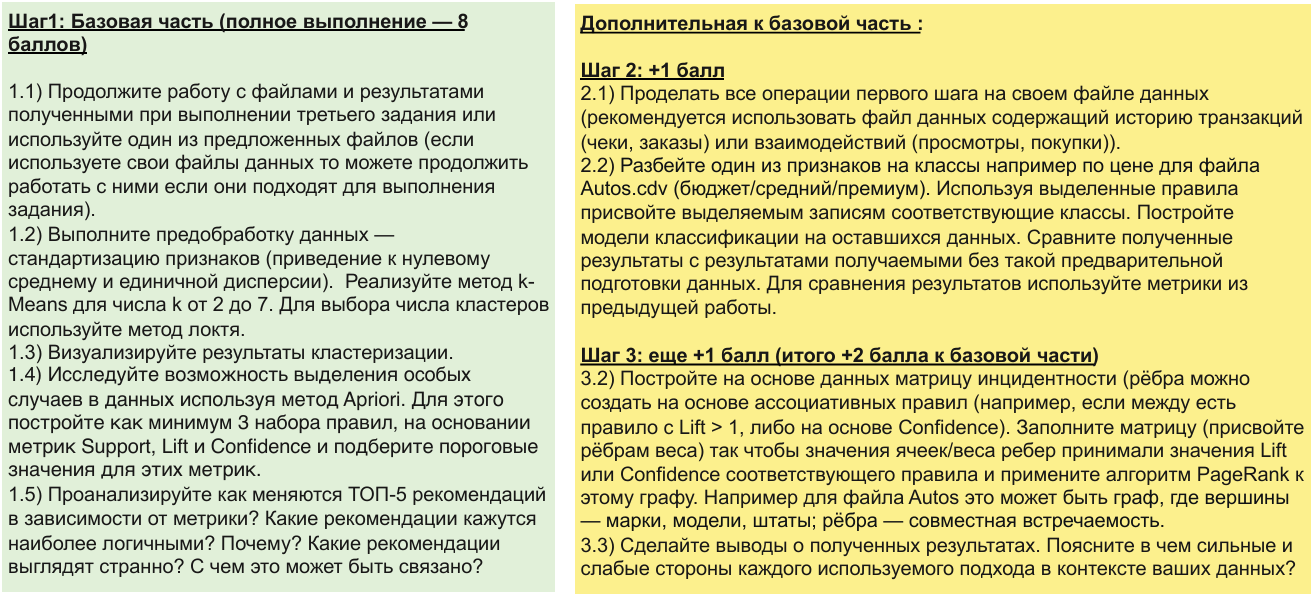